# Modelado: análisis de sentimiento en reseñas de hoteles
**Proyecto Integrador – Tópicos Avanzados de Programación (UAGRM)** · Consigna, sección **5.3 Modelos de machine learning**

Este notebook construye el modelado **sobre el pipeline de NLP del repositorio** (`src/nlp/preprocesamiento.py`) y usa
**exactamente la misma división** entrenamiento / prueba que generó `src/nlp/preparar_datos.py` (`data/train.csv` y `data/test.csv`).

Pasos:
1. Datos de entrada
2. Línea base
3. Modelos candidatos
4. Ajuste de hiperparámetros con validación cruzada
5. Tabla comparativa y modelo en producción
6. Evaluación final en el conjunto de prueba
7. Interpretación del modelo
8. Análisis de errores
9. Guardado de artefactos

**Requisito previo:** haber ejecutado `python -m src.nlp.preparar_datos` al menos una vez (genera `data/train.csv` y `data/test.csv`).

## Configuración

In [1]:
import sys
import json
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import joblib
import sklearn

warnings.filterwarnings('ignore')

# Raíz del proyecto: si el notebook está en notebooks/, la raíz es la carpeta de arriba
RAIZ = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(RAIZ))        # para poder hacer: import src.nlp.preprocesamiento

DATA = RAIZ / 'data'
ARTEFACTOS = RAIZ / 'artefactos'
SEED = 42
CLASES = ['negativo', 'neutro', 'positivo']

from src.nlp.preprocesamiento import crear_preprocesador   # el MISMO pipeline de NLP del repositorio

print('Raíz del proyecto:', RAIZ)
print('scikit-learn:', sklearn.__version__)

Raíz del proyecto: /home/appex/Escritorio/Serginho/topicos/hotel/REPO-PRUEBA-TOPICOS
scikit-learn: 1.8.0


# 1. Datos de entrada
Se cargan las particiones guardadas por `src/nlp/preparar_datos.py` (80 % / 20 %, estratificada, `random_state=42`, sin duplicados).
El conjunto de prueba **no se usa para ajustar nada** hasta la evaluación final.

In [2]:
for f in ['train.csv', 'test.csv']:
    if not (DATA / f).exists():
        raise FileNotFoundError(f'Falta data/{f}. Ejecuta primero en la terminal: python -m src.nlp.preparar_datos')

train = pd.read_csv(DATA / 'train.csv')
test = pd.read_csv(DATA / 'test.csv')

X_train, y_train = train['texto'], train['sentimiento']
X_test, y_test = test['texto'], test['sentimiento']

print('Entrenamiento:', len(train), '| Prueba:', len(test))
print('\nProporción de clases (entrenamiento):')
print(y_train.value_counts(normalize=True).round(3).loc[CLASES])

Entrenamiento: 1433 | Prueba: 359

Proporción de clases (entrenamiento):
sentimiento
negativo    0.279
neutro      0.159
positivo    0.562
Name: proportion, dtype: float64


## Métricas y validación cruzada
Métrica principal: **F1 macro** (trata igual a las tres clases, importante porque la clase neutra tiene pocos ejemplos).
También se mide F1 y recall de la clase **neutra**, que es la más difícil. La validación cruzada es estratificada, de 5 particiones, con semilla fija.

In [3]:
from sklearn.model_selection import StratifiedKFold, cross_validate, GridSearchCV
from sklearn.metrics import (make_scorer, f1_score, recall_score, accuracy_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

def f1_neutro(y_true, y_pred):
    return f1_score(y_true, y_pred, labels=['neutro'], average='macro', zero_division=0)

def recall_neutro(y_true, y_pred):
    return recall_score(y_true, y_pred, labels=['neutro'], average='macro', zero_division=0)

METRICAS = {
    'accuracy': 'accuracy',
    'f1_macro': 'f1_macro',
    'f1_neutro': make_scorer(f1_neutro),
    'recall_neutro': make_scorer(recall_neutro),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

# 2. Línea base
Un modelo que siempre predice la clase más frecuente (positivo). Si los modelos no lo superan con claridad, no aportan valor.

In [4]:
from sklearn.dummy import DummyClassifier

base = DummyClassifier(strategy='most_frequent')
r = cross_validate(base, X_train, y_train, cv=cv, scoring=METRICAS)
print(f"Línea base -> accuracy: {r['test_accuracy'].mean():.3f} | F1 macro: {r['test_f1_macro'].mean():.3f}")

Línea base -> accuracy: 0.562 | F1 macro: 0.240


# 3. Modelos candidatos
Se comparan **dos modelos** (de familias distintas) y se justifica cuál queda en producción:

- **Regresión logística** (candidata a producción): aprende un peso por término de forma conjunta, puede aprovechar bigramas
  (`no recom`, si la validación cruzada los elige), entrega probabilidades razonablemente calibradas y se interpreta con sus coeficientes.
  El desbalance de clases se trata con `class_weight='balanced'`, sin agregar ni eliminar reseñas.
- **Naive Bayes (Complement NB)**: modelo probabilístico muy rápido que asume independencia entre términos; es competitivo con pocos datos
  y la variante *Complement* está pensada para clases desbalanceadas. Sus probabilidades suelen ser sobreconfiadas.

Cada modelo se arma como un **único `Pipeline`**: `src.nlp.preprocesamiento.crear_preprocesador()` (normalización + TF-IDF) + clasificador.
Así, en cada partición de la validación cruzada el TF-IDF se ajusta solo con los datos de entrenamiento de esa partición (sin fuga de datos),
y el mismo pipeline completo es el que se guarda para el backend.

In [5]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import ComplementNB

def construir(clf):
    return Pipeline([
        ('prep', crear_preprocesador()),   # normalizar -> TF-IDF (src/nlp/preprocesamiento.py)
        ('clf', clf),
    ])

print(construir(LogisticRegression()))

Pipeline(steps=[('prep',
                 Pipeline(steps=[('normalizar', TextoNormalizador()),
                                 ('tfidf',
                                  TfidfVectorizer(min_df=2, ngram_range=(1, 2),
                                                  sublinear_tf=True,
                                                  token_pattern='\\S+'))])),
                ('clf', LogisticRegression())])


# 4. Ajuste de hiperparámetros con validación cruzada
`GridSearchCV` prueba combinaciones sobre **entrenamiento** y elige por F1 macro. Además de los parámetros del modelo, se prueba
el rango de n-gramas (unigramas frente a unigramas + bigramas) y la frecuencia mínima de los términos (`min_df`).

In [6]:
busquedas = {
    'Regresión logística': (
        construir(LogisticRegression(max_iter=1000, class_weight='balanced', random_state=SEED)),
        {'prep__tfidf__ngram_range': [(1, 1), (1, 2)],
         'prep__tfidf__min_df': [1, 2, 3],
         'clf__C': [0.1, 1, 10]},
    ),
    'Naive Bayes (Complement)': (
        construir(ComplementNB()),
        {'prep__tfidf__ngram_range': [(1, 1), (1, 2)],
         'prep__tfidf__min_df': [1, 2, 3],
         'clf__alpha': [0.1, 0.5, 1.0]},
    ),
}

mejores, parametros = {}, {}
for nombre, (pipe, grid) in busquedas.items():
    t0 = time.time()
    gs = GridSearchCV(pipe, grid, scoring='f1_macro', cv=cv, n_jobs=1, refit=True)
    gs.fit(X_train, y_train)
    mejores[nombre] = gs.best_estimator_
    parametros[nombre] = {k: str(v) for k, v in gs.best_params_.items()}
    print(f'{nombre}  ({time.time() - t0:.0f} s)')
    print(f'  mejores parámetros: {gs.best_params_}')
    print(f'  F1 macro (CV): {gs.best_score_:.4f}\n')

Regresión logística  (250 s)
  mejores parámetros: {'clf__C': 1, 'prep__tfidf__min_df': 1, 'prep__tfidf__ngram_range': (1, 1)}
  F1 macro (CV): 0.7202



Naive Bayes (Complement)  (97 s)
  mejores parámetros: {'clf__alpha': 0.1, 'prep__tfidf__min_df': 3, 'prep__tfidf__ngram_range': (1, 2)}
  F1 macro (CV): 0.6505



# 5. Tabla comparativa y modelo en producción
Todas las métricas son de **validación cruzada sobre entrenamiento**. El modelo en producción es el de mayor **F1 macro**.
Si dos modelos quedan dentro de la desviación (`Desv. F1 macro`), la diferencia es ruido y se puede preferir el más simple o el mejor calibrado.

In [7]:
def fila(nombre, estimador):
    t0 = time.time()
    r = cross_validate(estimador, X_train, y_train, cv=cv, scoring=METRICAS)
    return {
        'Modelo': nombre,
        'Accuracy': r['test_accuracy'].mean(),
        'F1 macro': r['test_f1_macro'].mean(),
        'Desv. F1 macro': r['test_f1_macro'].std(),
        'F1 neutro': r['test_f1_neutro'].mean(),
        'Recall neutro': r['test_recall_neutro'].mean(),
        'Tiempo CV (s)': time.time() - t0,
    }

filas = [fila('Línea base', DummyClassifier(strategy='most_frequent'))]
for nombre, est in mejores.items():
    filas.append(fila(nombre, est))

tabla = pd.DataFrame(filas).set_index('Modelo').round(4)
NOMBRE_FINAL = tabla.drop(index='Línea base')['F1 macro'].idxmax()
print(tabla.to_string())
print(f'\nModelo en producción: {NOMBRE_FINAL}')

                          Accuracy  F1 macro  Desv. F1 macro  F1 neutro  Recall neutro  Tiempo CV (s)
Modelo                                                                                               
Línea base                  0.5618    0.2398          0.0003     0.0000         0.0000         0.0395
Regresión logística         0.7942    0.7202          0.0241     0.4455         0.4566        18.0723
Naive Bayes (Complement)    0.8116    0.6505          0.0368     0.2272         0.1365         5.6289

Modelo en producción: Regresión logística


# 6. Evaluación final en el conjunto de prueba
Se evalúa **una sola vez**, solo con el modelo elegido, y se compara con la línea base.

In [8]:
modelo_final = mejores[NOMBRE_FINAL]
pred = modelo_final.predict(X_test)

pred_base = DummyClassifier(strategy='most_frequent').fit(X_train, y_train).predict(X_test)

acc = accuracy_score(y_test, pred)
f1m = f1_score(y_test, pred, average='macro')
print(f'Modelo: {NOMBRE_FINAL}')
print(f'  Accuracy: {acc:.4f} | F1 macro: {f1m:.4f}')
print('Línea base:')
print(f'  Accuracy: {accuracy_score(y_test, pred_base):.4f} | '
      f'F1 macro: {f1_score(y_test, pred_base, average="macro", zero_division=0):.4f}\n')
print(classification_report(y_test, pred, labels=CLASES, digits=3, zero_division=0))

Modelo: Regresión logística
  Accuracy: 0.7855 | F1 macro: 0.7068
Línea base:
  Accuracy: 0.5627 | F1 macro: 0.2400

              precision    recall  f1-score   support

    negativo      0.796     0.860     0.827       100
      neutro      0.397     0.439     0.417        57
    positivo      0.910     0.847     0.877       202

    accuracy                          0.786       359
   macro avg      0.701     0.715     0.707       359
weighted avg      0.797     0.786     0.790       359



## Matriz de confusión

               pred negativo  pred neutro  pred positivo
real negativo             86           13              1
real neutro               16           25             16
real positivo              6           25            171


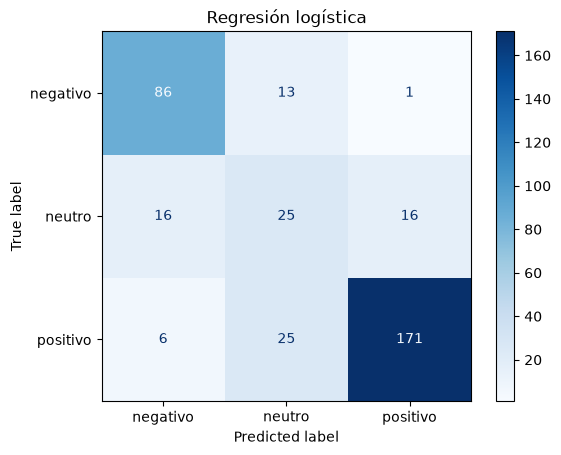

In [9]:
import matplotlib.pyplot as plt

print(pd.DataFrame(confusion_matrix(y_test, pred, labels=CLASES),
                   index=[f'real {c}' for c in CLASES],
                   columns=[f'pred {c}' for c in CLASES]))

ConfusionMatrixDisplay.from_predictions(y_test, pred, labels=CLASES, cmap='Blues')
plt.title(NOMBRE_FINAL)
plt.show()

# 7. Interpretación del modelo
Términos que más empujan hacia cada clase en la **regresión logística** (sus coeficientes). Sirve para explicar cómo decide el modelo,
aunque el modelo en producción sea otro. Los términos son **raíces** del stemming (p. ej. `recom` de *recomiendo*); fíjate en cómo aparecen las negaciones (`no`).

In [10]:
lr = mejores['Regresión logística']
clf = lr.named_steps['clf']
terminos = np.array(lr.named_steps['prep'].named_steps['tfidf'].get_feature_names_out())

for i, clase in enumerate(clf.classes_):
    top = np.argsort(clf.coef_[i])[-10:][::-1]
    print(str(clase).upper(), '->', ', '.join(terminos[top]))

NEGATIVO -> suci, mal, no, pesim, peor, ni, viej, nad, malisim, estrell
NEUTRO -> bien, per, acept, bastant, preci, pequeñ, poc, problem, buffet, buen
POSITIVO -> muy, excelent, encant, perfect, recomend, estupend, dud, tod, ampli, magnif


# 8. Análisis de errores
Reseñas del conjunto de prueba que el modelo clasificó mal. Revisa los ejemplos y escribe en la celda de abajo **por qué** falló
(por ejemplo: reseñas de 3 estrellas con elogios y quejas mezclados, puntuación que no coincide con el texto, ironía, textos muy cortos).

In [11]:
proba = modelo_final.predict_proba(X_test).max(axis=1)
resultado = test.assign(prediccion=pred, confianza=proba.round(2))
errores = resultado[resultado['sentimiento'] != resultado['prediccion']]

print(f'Errores: {len(errores)} de {len(resultado)}')
print('\nReal (filas) vs predicho (columnas), solo errores:')
print(pd.crosstab(errores['sentimiento'], errores['prediccion']))

pd.set_option('display.max_colwidth', 250)
errores[['rank', 'sentimiento', 'prediccion', 'confianza', 'texto']].head(10)

Errores: 77 de 359

Real (filas) vs predicho (columnas), solo errores:
prediccion   negativo  neutro  positivo
sentimiento                            
negativo            0      13         1
neutro             16       0        16
positivo            6      25         0


,rank,sentimiento,prediccion,confianza,texto
0,3,neutro,negativo,0.70,"No les quiero ser mala ni nada, pero lo que voy a decir es la pura verdad:No debería ser un hotel de 4* estrellas, sino que de 3. La comida es variada pero lo que se dice de la carne y las patatas fritas, estaban super blandas, lo único normal er..."
3,4,positivo,neutro,0.68,"Buenas, he estado este fin de semana (30/5/2013-2/6/2013), el año pasado tambien estuve, por lo general bastante bien en comida y atencion de los camareros ,pero vi un problema... el año pasado y este año me fije mejor.... para bajar a la piscina..."
7,2,negativo,neutro,0.41,"Bueno pues el hotel está lo que es la sala de juegos, el bar, la piscina... eso está de lujo... precioso y muy acogedor... en perfecto estado... pero las habitaciones.... k malas son... no se si hay mejor habitación pero yo tenía una doble y supe..."
9,3,neutro,negativo,0.60,"Estuvimos alojados en la habitación 107, da a una especie de patio interior. Alrededor del patio están dispuestas las habitaciones. La puerta de la habitación da directamente al patio. Así que en cuanto pasa alguien por ahí se escucha todo. Las h..."
22,2,negativo,neutro,0.52,"el parking es pequeño y suele estar lleno. las habitaciones grsndes pero viejas, internet carisimo y lento y malo. Las zonas comunes son de los años 70 y el trato no es especialmente bueno. ojo al minibar, bebidas caducadas"
27,4,positivo,neutro,0.53,"he estado en tres cincos estrellas, y este no les llega a esta categoria, le sobra una, pero el hotel esta muy bien , habitaciones y baño normales, buena limpieza camas en perfecto estado, el buffet excelente, animacion y espectaculos algo flojos..."
31,3,neutro,positivo,0.40,"Las vacaciones fueron la última semana de agosto 2012, el servicio nos pareció bueno , las habitaciones muy limpias sino fuera por la cantidad tan horrorosa de hormigas que hay , las instalaciones muy buenas pero la comida escasa y sobre todo la ..."
39,3,neutro,negativo,0.61,"En viaje de Luna de Miel nos encontramos con que el hotel de ""4 estrellas"" no tiene cama matrimonial. No es que no tenía disponible ehh, simplemente no tiene!!!. Te juntan dos hermosos sommiers súper cómodos, pero cada uno con su ropa de cama, po..."
51,4,positivo,neutro,0.55,"Es la cuarta vez que nos alojamos en este hotel, en mi anterior opinión ya dije que por lo que cuesta no se puede pedir más, pero además este año hay que sumarle que se ha notado el cambio de gestion, para bien claro. Un buen servicio y buena ate..."
52,4,positivo,neutro,0.43,"Se trata de un hotel muy pequeño, situado algo lejos del centro de Granada. Para llegar en transporte hay dos autobuses; uno deja en el centro y el otro deja al lado de la Alhambra. Para quien vaya en coche es muy conveniente, está en la carreter..."


**Explicación de los errores:**


- **Clase que más se confunde:** la neutra. El modelo se equivocó en 80 de las 359 reseñas de prueba, y 69 de esos errores involucran a la clase neutra. De las 57 reseñas neutras, 37 las clasificó mal: 15 como negativas y 22 como positivas. Solo 11 errores fueron entre negativo y positivo.
- **Qué tienen en común:** las reseñas neutras vienen de 3 estrellas y suelen mezclar cosas buenas y malas, por eso se parecen a las positivas y a las negativas. Además, en la revisión manual del etiquetado solo el 80 % de las neutras coincidía con su etiqueta, frente al 95 % de las otras clases.
- **Qué se podría mejorar:** revisar las etiquetas de 3 estrellas, ajustar el peso de la clase neutra y usar también el título de la reseña como entrada.

# 9. Guardado de artefactos y prueba de uso
Se guarda el **pipeline completo** (normalización + TF-IDF + modelo) en `artefactos/`, junto con las métricas para el backend.
Quien cargue `modelo_final.joblib` debe tener `src/nlp/preprocesamiento.py` importable (raíz del proyecto en el PYTHONPATH), porque el archivo guarda una referencia a `TextoNormalizador`.

In [12]:
ARTEFACTOS.mkdir(exist_ok=True)
joblib.dump(modelo_final, ARTEFACTOS / 'modelo_final.joblib')

reporte = classification_report(y_test, pred, labels=CLASES, output_dict=True, zero_division=0)
metricas = {
    'modelo_en_produccion': NOMBRE_FINAL,
    'mejores_parametros': parametros,
    'validacion_cruzada': tabla.reset_index().to_dict(orient='records'),
    'prueba': {
        'accuracy': round(float(acc), 4),
        'f1_macro': round(float(f1m), 4),
        'por_clase': {c: {k: round(float(v), 4) for k, v in reporte[c].items()} for c in CLASES},
    },
    'clases': CLASES,
    'semilla': SEED,
    'version_scikit_learn': sklearn.__version__,
}
(ARTEFACTOS / 'metricas_modelado.json').write_text(
    json.dumps(metricas, indent=2, ensure_ascii=False), encoding='utf-8')
tabla.to_csv(ARTEFACTOS / 'tabla_comparativa_modelos.csv')
print('Guardado en artefactos/: modelo_final.joblib, metricas_modelado.json, tabla_comparativa_modelos.csv')

# prueba de uso: de texto crudo a predicción con probabilidad
for t in ['Habitación sucia y personal grosero, no volvería nunca',
          'Hotel excelente, desayuno riquísimo y muy buena ubicación']:
    p = modelo_final.predict_proba([t])[0]
    print(t, '->', {str(c): round(float(x), 2) for c, x in zip(modelo_final.classes_, p)})

Guardado en artefactos/: modelo_final.joblib, metricas_modelado.json, tabla_comparativa_modelos.csv
Habitación sucia y personal grosero, no volvería nunca -> {'negativo': 0.78, 'neutro': 0.09, 'positivo': 0.13}
Hotel excelente, desayuno riquísimo y muy buena ubicación -> {'negativo': 0.04, 'neutro': 0.11, 'positivo': 0.85}
